# Urban Traffic Simulation and Decision Support

Companion notebook for the [SimWeave blog post](https://notabot123.github.io/simweave/blog/road-traffic/).

Covers:
- **Single junction** — signalised crossroads, occupancy and queue plots
- **2×2 network** — four junctions connected by dual carriageways
- **Scenario: roundabout replacement** — signal vs roundabout at the busiest junction
- **Signal timing sweep** — 2-D sensitivity across two junctions with different traffic profiles

In [1]:
# Uncomment to install if running outside Binder
# !pip install 'simweave[viz]>=0.8.1' kaleido

import numpy as np
import simweave as sw
from simweave.roads import (
    Road, DualCarriageway, Intersection, RoadNetwork,
    SignalPhase, TrafficSignal, VehicleArrivalProcess,
    RoadOccupancyRecorder, IntersectionQueueRecorder,
    Roundabout, Handedness,
)
from simweave.reliability import sensitivity_sweep
from simweave.viz import set_default_theme
import plotly.graph_objects as go
import plotly.io as pio
import pathlib

IMG_DIR     = pathlib.Path('img')
IMG_DIR.mkdir(exist_ok=True)
SIM_SECONDS = 3_600
DT          = 1.0
SPEED_50    = 13.9
SPEED_30    = 8.3

# Apply dark theme to all SimWeave plot helpers and manual Plotly figures
set_default_theme('dark')
pio.templates.default = 'plotly_dark'

print('SimWeave', sw.__version__)

SimWeave 0.8.1


## 1  Single Signalised Junction

In [2]:
def make_signal(ns_green, ew_green, roads_ns, roads_ew):
    return TrafficSignal([
        SignalPhase(green_roads=roads_ns, duration=ns_green, name='NS_green'),
        SignalPhase(green_roads=roads_ew, duration=ew_green, name='EW_green'),
    ])


def build_single_junction(ns_green=45.0, ew_green=30.0,
                           rates=(0.20, 0.15, 0.25, 0.18), seed=42):
    '''Build a 4-arm signalised junction.  rates = (N, S, E, W) vehicles/second.'''
    rng = np.random.default_rng(seed)
    L   = 200.0

    road_n, road_s = Road(L, SPEED_50, lanes=2, name='north'), Road(L, SPEED_50, lanes=2, name='south')
    road_e, road_w = Road(L, SPEED_50, lanes=2, name='east'),  Road(L, SPEED_50, lanes=2, name='west')
    exits = [Road(L, SPEED_50, lanes=2, name=f'exit_{d}') for d in ('n','s','e','w')]

    signal   = make_signal(ns_green, ew_green, [road_n, road_s], [road_e, road_w])
    junction = Intersection(
        signal=signal,
        rng=np.random.default_rng(rng.integers(0, 2**32)),
        name='crossroads',
    )
    for road in (road_n, road_s, road_e, road_w):
        junction.add_approach(road)
        road.outlet = junction
    for ex in exits:
        junction.add_exit(ex, weight=1.0)

    r_n, r_s, r_e, r_w = rates
    arrivals = [
        VehicleArrivalProcess(lambda r, rt=r_n: r.exponential(1.0/rt), road_n, rng=np.random.default_rng(1)),
        VehicleArrivalProcess(lambda r, rt=r_s: r.exponential(1.0/rt), road_s, rng=np.random.default_rng(2)),
        VehicleArrivalProcess(lambda r, rt=r_e: r.exponential(1.0/rt), road_e, rng=np.random.default_rng(3)),
        VehicleArrivalProcess(lambda r, rt=r_w: r.exponential(1.0/rt), road_w, rng=np.random.default_rng(4)),
    ]

    occ  = RoadOccupancyRecorder([road_n, road_s, road_e, road_w])
    qrec = IntersectionQueueRecorder(junction)

    net = RoadNetwork()
    net.add_signal(signal)
    net.add_intersection(junction)
    for r in [road_n, road_s, road_e, road_w] + exits:
        net.add_road(r)
    for a in arrivals:
        net.add_arrival_process(a)
    net.add_recorder(occ)
    net.add_recorder(qrec)

    return net, junction, arrivals, occ, qrec


net, junction, arrivals, occ, qrec = build_single_junction()
env = sw.SimEnvironment(dt=DT, end=SIM_SECONDS)
net.register_all(env)
env.run()

total_gen = sum(a.generated for a in arrivals)
print(f'Vehicles generated : {total_gen:,}')
print(f'Cleared junction   : {junction.total_vehicles:,}')
print(f'Delayed at red     : {junction.total_delayed:,}  ({100*junction.total_delayed/total_gen:.0f}%)')

Vehicles generated : 2,839
Cleared junction   : 2,819
Delayed at red     : 1,467  (52%)


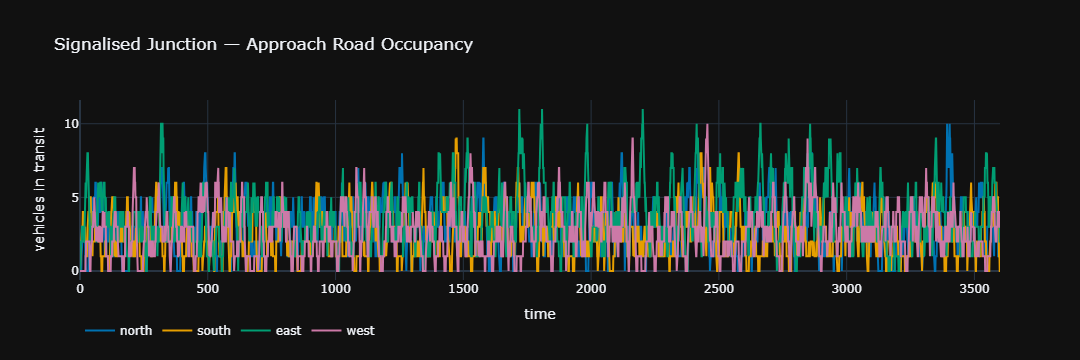

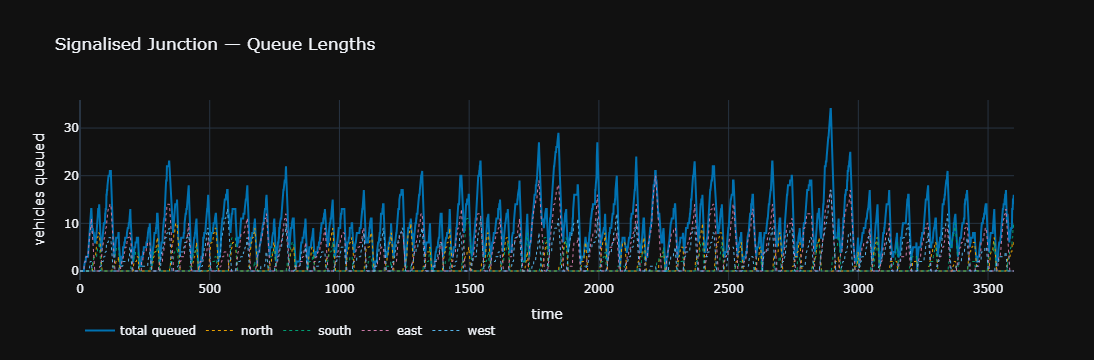

In [3]:
fig_occ = sw.plot_road_occupancy(occ, title='Signalised Junction — Approach Road Occupancy')
fig_occ.show()
fig_occ.write_image(str(IMG_DIR / 'junction_occupancy.png'), width=1000, height=500, scale=2)

fig_q = sw.plot_intersection_queues(qrec, title='Signalised Junction — Queue Lengths')
fig_q.show()
fig_q.write_image(str(IMG_DIR / 'junction_queues.png'), width=1000, height=500, scale=2)

## 2  Scenario: Signal vs Roundabout

Compare a signalised junction against a UK roundabout under identical arrival rates.
**Note:** `Roundabout` uses `add_entry(road)` (not `add_approach`).

In [4]:
def build_roundabout_junction(seed=42):
    '''Same 4-arm layout as the signalised junction, but with a roundabout.'''
    rng = np.random.default_rng(seed)
    L   = 200.0

    road_n, road_s = Road(L, SPEED_50, lanes=2, name='north'), Road(L, SPEED_50, lanes=2, name='south')
    road_e, road_w = Road(L, SPEED_50, lanes=2, name='east'),  Road(L, SPEED_50, lanes=2, name='west')
    exits = [Road(L, SPEED_50, lanes=2, name=f'exit_{d}') for d in ('n','s','e','w')]

    # Roundabout uses add_entry (not add_approach) for incoming arms
    rb = Roundabout(
        max_circulating=8,
        transit_time=6.0,
        handedness=Handedness.LEFT,
        rng=np.random.default_rng(rng.integers(0, 2**32)),
        name='roundabout',
    )
    for road in (road_n, road_s, road_e, road_w):
        rb.add_entry(road)
        road.outlet = rb
    for ex in exits:
        rb.add_exit(ex, weight=1.0)

    arrivals = [
        VehicleArrivalProcess(lambda r: r.exponential(1.0/0.20), road_n, rng=np.random.default_rng(1)),
        VehicleArrivalProcess(lambda r: r.exponential(1.0/0.15), road_s, rng=np.random.default_rng(2)),
        VehicleArrivalProcess(lambda r: r.exponential(1.0/0.25), road_e, rng=np.random.default_rng(3)),
        VehicleArrivalProcess(lambda r: r.exponential(1.0/0.18), road_w, rng=np.random.default_rng(4)),
    ]

    qrec = IntersectionQueueRecorder(rb)
    net  = RoadNetwork()
    net.add_roundabout(rb)
    for r in [road_n, road_s, road_e, road_w] + exits:
        net.add_road(r)
    for a in arrivals:
        net.add_arrival_process(a)
    net.add_recorder(qrec)

    return net, rb, arrivals, qrec


# Run both
net_s, j_s, arr_s, _, _ = build_single_junction(seed=42)
env_s = sw.SimEnvironment(dt=DT, end=SIM_SECONDS)
net_s.register_all(env_s)
env_s.run()

net_r, j_r, arr_r, _ = build_roundabout_junction(seed=42)
env_r = sw.SimEnvironment(dt=DT, end=SIM_SECONDS)
net_r.register_all(env_r)
env_r.run()

gen_s = sum(a.generated for a in arr_s)
gen_r = sum(a.generated for a in arr_r)

# Intersection has total_vehicles; Roundabout has total_exited (vehicles that cleared)
results = {
    'Signal':     {'through': j_s.total_vehicles, 'delay_pct': 100*j_s.total_delayed/max(1,gen_s)},
    'Roundabout': {'through': j_r.total_exited,   'delay_pct': 100*j_r.total_delayed/max(1,gen_r)},
}
for name, r in results.items():
    print(f'{name:12s}  throughput={r["through"]:,}  delay={r["delay_pct"]:.1f}%')

Signal        throughput=2,819  delay=51.7%
Roundabout    throughput=2,828  delay=17.2%


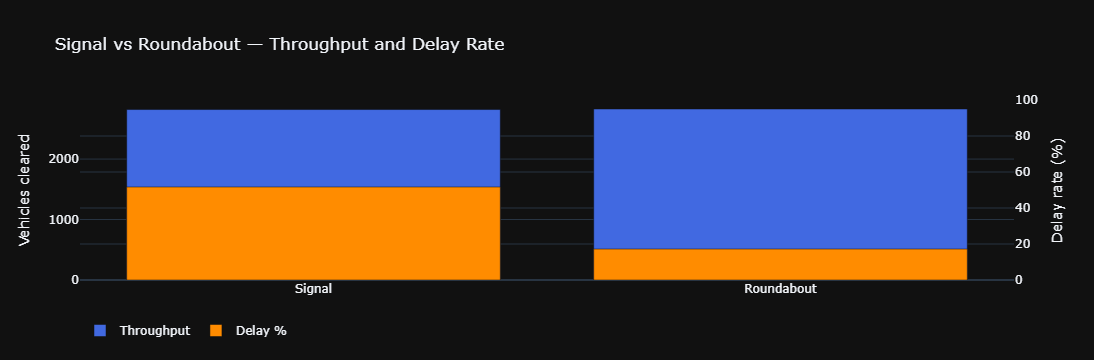

In [5]:
labels = list(results.keys())
fig_cmp = go.Figure()
fig_cmp.add_trace(go.Bar(
    x=labels, y=[results[k]['through']   for k in labels],
    name='Throughput', marker_color='royalblue',
))
fig_cmp.add_trace(go.Bar(
    x=labels, y=[results[k]['delay_pct'] for k in labels],
    name='Delay %', marker_color='darkorange', yaxis='y2',
))
fig_cmp.update_layout(
    title='Signal vs Roundabout — Throughput and Delay Rate',
    yaxis =dict(title='Vehicles cleared'),
    yaxis2=dict(title='Delay rate (%)', overlaying='y', side='right', range=[0, 100]),
    barmode='group',
    legend={'orientation': 'h', 'y': -0.2},
)
fig_cmp.show()
fig_cmp.write_image(str(IMG_DIR / 'scenario_signal_vs_roundabout.png'), width=800, height=500, scale=2)

## 3  Signal Timing Sensitivity — Two Junctions

We sweep NS green duration at two junctions simultaneously:
- **Junction A** — NS-heavy traffic (North/South dominant): benefits most from more NS green
- **Junction B** — EW-heavy traffic (East/West dominant): benefits most from *less* NS green (= more EW green)

Total network delay is the sum of both junctions' delayed vehicles.
The heatmap reveals a genuine 2-D optimum where both junctions are reasonably served.

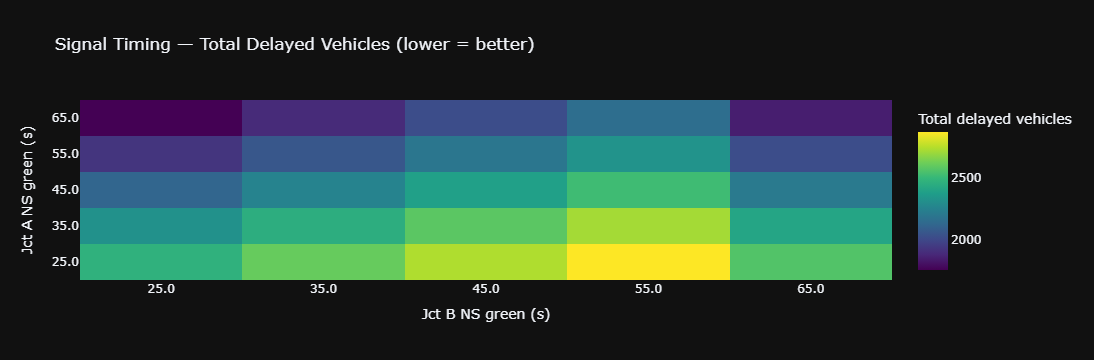

In [6]:
CYCLE = 75.0   # fixed total cycle time (s); EW green = CYCLE - NS green

def junction_delayed(ns_green, rates, seed):
    '''Run one junction and return total delayed vehicles.'''
    ew_green = CYCLE - ns_green
    if ew_green <= 5 or ns_green <= 5:
        return 9999   # degenerate timing — penalise
    net, j, _, _, _ = build_single_junction(
        ns_green=ns_green, ew_green=ew_green,
        rates=rates, seed=seed,
    )
    env = sw.SimEnvironment(dt=DT, end=SIM_SECONDS)
    net.register_all(env)
    env.run()
    return j.total_delayed


def network_delay(ns_green_A, ns_green_B, seed):
    '''Combined delay across two junctions with different traffic profiles.'''
    # Junction A: NS-heavy (more traffic from North/South)
    delay_A = junction_delayed(ns_green_A, rates=(0.28, 0.22, 0.10, 0.08), seed=seed)
    # Junction B: EW-heavy (more traffic from East/West)
    delay_B = junction_delayed(ns_green_B, rates=(0.10, 0.08, 0.28, 0.22), seed=seed+100)
    return float(delay_A + delay_B)


timing_result = sensitivity_sweep(
    network_delay,
    param1_name='Jct A NS green (s)',  param1_values=[25, 35, 45, 55, 65],
    param2_name='Jct B NS green (s)',  param2_values=[25, 35, 45, 55, 65],
    metric_name='Total delayed vehicles',
    n_runs=6,
    seed=0,
)

fig_heat = sw.plot_sensitivity_surface(
    timing_result, chart_type='heatmap',
    title='Signal Timing — Total Delayed Vehicles (lower = better)',
)
fig_heat.show()
fig_heat.write_image(str(IMG_DIR / 'signal_timing_heatmap.png'), width=700, height=600, scale=2)

The heatmap shows that **Junction A** benefits from longer NS green (the optimum is toward
the high end of its axis) while **Junction B** benefits from shorter NS green (= more EW time).
The combined optimum is the cell with minimum total delay — a simple but concrete decision-support output.

## Summary — Exported Images

| File | Description |
|---|---|
| `junction_occupancy.png` | Approach road occupancy at single signalised junction |
| `junction_queues.png` | Queue lengths over simulation time |
| `scenario_signal_vs_roundabout.png` | Throughput and delay: signal vs roundabout |
| `signal_timing_heatmap.png` | 2-D sensitivity: optimal NS green for two junctions |